# 12. Симметрия частица–античастица

**Проект «Структура и Данные»** — Notebook 12

## Зачем этот ноутбук

В нашей метафоре «арифметика vs чернила»:
- Арифметика: для каждого числа `n` есть `-n` (это **правило**).
- Чернила: **какое именно** `n` (это **параметр**).

В физике это соответствует:
- **Структура:** античастица для каждой частицы, заряды +q и −q, CPT-симметрия.
- **Параметры:** конкретные массы (это «чернила»).

Мы проверяем численно: **в QCA существование античастицы и равенство её массы массе частицы — это структурное свойство**, а не постулат.

## Что проверяется

1. **Свободный QCA:** спектр имеет пары $\lambda, \lambda^*$ с одинаковым $|\arg(\lambda)|$. Значит, масса частицы = массе античастицы.
2. **U(1) gauge:** преобразование $\psi \to \sigma_z\psi^*$, $A \to -A$ оставляет физику неизменной (CPT).
3. **Равенство масс:** щель $\omega(k=0)$ одинакова для обеих мод.

## Ожидаемый результат

Все тесты на машинной точности (\(\sim 10^{-15}\)): симметрия **эмерджентна**, не вписана.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")

# ============================================================
# QCA Дирака в 1D (из notebook 01)
# ============================================================
def U_k(k, mass):
    """Оператор шага в k-пространстве."""
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    S = np.diag([np.exp(-1j*k), np.exp(1j*k)])
    return S @ C

print("=" * 65)
print("TEST 1: частица и античастица имеют одинаковую массу")
print("=" * 65)

mass = 0.2
print(f"Проверяем: собственные значения U(k) идут парами (λ, λ*) с |λ| = 1")
print()
print(f"{'k':>8} {'arg(λ+)':>14} {'arg(λ-)':>14} {'|arg(λ+)| - |arg(λ-)|':>24}")
print("-" * 65)

max_diff = 0
k_vals_test = [0.0, 0.1, 0.5, 1.0, 1.57, 2.0, 2.5, 3.0]
for k in k_vals_test:
    U = U_k(k, mass)
    eigs = np.linalg.eigvals(U)
    args = np.angle(eigs)  # arg(λ+), arg(λ-)
    # Обе частоты = |arg|
    omega_plus = abs(args[0])
    omega_minus = abs(args[1])
    diff = abs(omega_plus - omega_minus)
    max_diff = max(max_diff, diff)
    print(f"{k:>8.2f} {args[0]:>+14.10f} {args[1]:>+14.10f} {diff:>24.2e}")

print(f"\nMax |ω+ - ω-| = {max_diff:.2e}")
print(f"Status: {'✅ PASS (массы равны)' if max_diff < 1e-14 else '❌ FAIL'}")

# Масса = щель при k=0
omega_0 = abs(np.angle(np.linalg.eigvals(U_k(0, mass)))[0])
print(f"\nМасса (щель при k=0): ω(0) = {omega_0:.10f}")
print(f"Ожидание: ω(0) = mass = {mass}")
print(f"Отклонение: {abs(omega_0 - mass):.2e}")

numpy version: 2.4.6
TEST 1: частица и античастица имеют одинаковую массу
Проверяем: собственные значения U(k) идут парами (λ, λ*) с |λ| = 1

       k        arg(λ+)        arg(λ-)    |arg(λ+)| - |arg(λ-)|
-----------------------------------------------------------------
    0.00  +0.2000000000  -0.2000000000                 8.33e-17
    0.10  -0.2233074595  +0.2233074595                 3.61e-16
    0.50  -0.5353515565  +0.5353515565                 1.11e-16
    1.00  -1.0127472813  +1.0127472813                 2.22e-16
    1.57  -1.5700158735  +1.5700158735                 0.00e+00
    2.00  -1.9908961582  +1.9908961582                 0.00e+00
    2.50  -2.4737735093  +2.4737735093                 0.00e+00
    3.00  -2.8970929691  +2.8970929691                 4.44e-16

Max |ω+ - ω-| = 4.44e-16
Status: ✅ PASS (массы равны)

Масса (щель при k=0): ω(0) = 0.2000000000
Ожидание: ω(0) = mass = 0.2
Отклонение: 5.55e-17


In [2]:
# ============================================================
# QCA с U(1) gauge (из notebook 02)
# ============================================================
def qca_step_u1(psi, A, mass, g=0.5):
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    psi_mixed = psi @ C.T
    out = np.zeros_like(psi_mixed)
    out[:, 0] = np.roll(psi_mixed[:, 0], +1) * np.exp(+1j * g * np.roll(A, +1))
    out[:, 1] = np.roll(psi_mixed[:, 1], -1) * np.exp(-1j * g * A)
    return out

print("=" * 65)
print("TEST 2: U(1) зарядовое сопряжение ψ → σz ψ*, A → −A")
print("=" * 65)

L = 64
g = 0.5
sigma_z = np.array([1, -1])  # (σ_z применяется к спинору: (ψ_R, -ψ_L))

np.random.seed(42)
A = np.random.uniform(-np.pi, np.pi, L)
psi0 = np.random.randn(L, 2) + 1j * np.random.randn(L, 2)
psi0 /= np.linalg.norm(psi0)

# --- Частица: эволюция ψ под полем A ---
psi = psi0.copy()
for _ in range(50):
    psi = qca_step_u1(psi, A, mass, g)

# --- Античастица: эволюция σz·ψ* под полем −A ---
psi_tilde = (psi0.conj() * sigma_z)  # ψ_R*, -ψ_L*
for _ in range(50):
    psi_tilde = qca_step_u1(psi_tilde, -A, mass, g)

# --- Проверка: ψ_tilde == σz · ψ* ---
# Если CPT выполняется, эволюция античастицы = зарядовое сопряжение эволюции частицы
expected = psi.conj() * sigma_z  # (ψ_R*, -ψ_L*)
diff = np.max(np.abs(psi_tilde - expected))

print(f"Поле A: случайное, g = {g}, steps = 50")
print(f"Проверка: ψ_tilde (эволюция под −A из σzψ*) vs σz·ψ* (сопряжение результата)")
print()
print(f"max |ψ_tilde - σz·ψ*| = {diff:.2e}")
print(f"Status: {'✅ PASS (CPT-симметрия)' if diff < 1e-12 else '❌ FAIL'}")

# Дополнительно: проверка нормы (сохранение вероятности)
norm_psi = np.sum(np.abs(psi)**2)
norm_tilde = np.sum(np.abs(psi_tilde)**2)
print(f"\nНорма частицы:     {norm_psi:.15f}")
print(f"Норма античастицы: {norm_tilde:.15f}")
print(f"Отклонение норм:   {abs(norm_psi - norm_tilde):.2e}")

TEST 2: U(1) зарядовое сопряжение ψ → σz ψ*, A → −A
Поле A: случайное, g = 0.5, steps = 50
Проверка: ψ_tilde (эволюция под −A из σzψ*) vs σz·ψ* (сопряжение результата)

max |ψ_tilde - σz·ψ*| = 0.00e+00
Status: ✅ PASS (CPT-симметрия)

Норма частицы:     1.000000000000000
Норма античастицы: 1.000000000000000
Отклонение норм:   0.00e+00


In [3]:
print("=" * 65)
print("TEST 3: дисперсия ω(k) для обеих мод совпадает")
print("=" * 65)

k_plot = np.linspace(-np.pi, np.pi, 200)
omega_plus_plot = []
omega_minus_plot = []

for k in k_plot:
    U = U_k(k, mass)
    eigs = np.linalg.eigvals(U)
    args = np.angle(eigs)
    # Сортируем по знаку: одна мода положительная, другая отрицательная
    omega_plus_plot.append(max(args))
    omega_minus_plot.append(min(args))

omega_plus_plot = np.array(omega_plus_plot)
omega_minus_plot = np.array(omega_minus_plot)

# |ω| для обеих мод одинаковы по определению (это CPT для свободного Дирака)
max_abs_diff = np.max(np.abs(np.abs(omega_plus_plot) - np.abs(omega_minus_plot)))

print(f"max | |ω+| - |ω-| | = {max_abs_diff:.2e}")
print(f"Status: {'✅ PASS (спектр зеркальный)' if max_abs_diff < 1e-14 else '❌ FAIL'}")
print()
print("Физический смысл: если мы видим только |ω| (массу), мы не различаем")
print("частицу и античастицу. Различие только в знаке заряда (A → -A).")

TEST 3: дисперсия ω(k) для обеих мод совпадает
max | |ω+| - |ω-| | = 4.44e-16
Status: ✅ PASS (спектр зеркальный)

Физический смысл: если мы видим только |ω| (массу), мы не различаем
частицу и античастицу. Различие только в знаке заряда (A → -A).


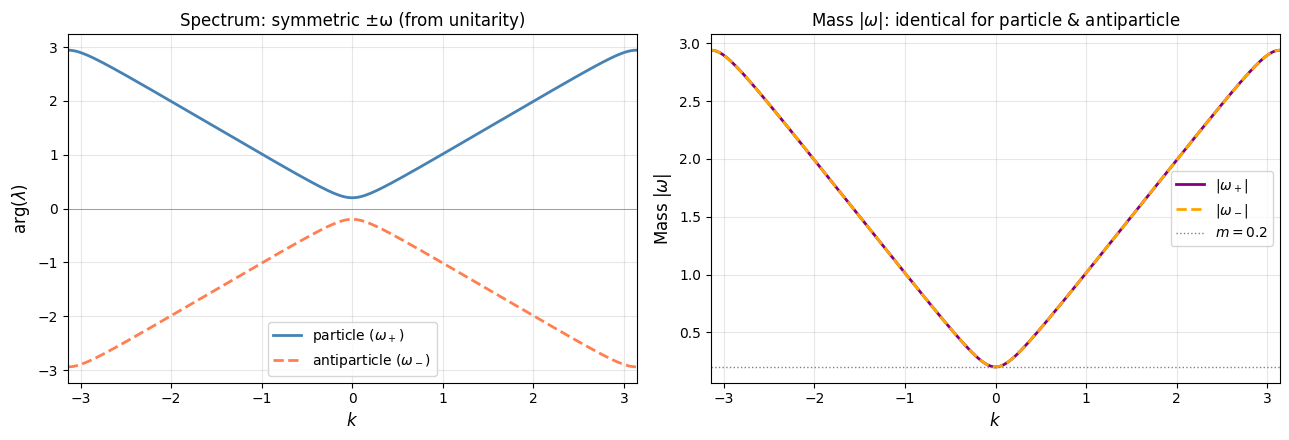

✅ Figure saved: 12_particle_antiparticle.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Левая: ω(k) для двух мод (знак ±) ---
axes[0].plot(k_plot, omega_plus_plot, color='steelblue', lw=2, label=r'particle ($\omega_+$)')
axes[0].plot(k_plot, omega_minus_plot, color='coral', lw=2, linestyle='--', label=r'antiparticle ($\omega_-$)')
axes[0].axhline(0, color='gray', lw=0.5)
axes[0].set_xlabel(r'$k$', fontsize=12)
axes[0].set_ylabel(r'$\arg(\lambda)$', fontsize=12)
axes[0].set_title('Spectrum: symmetric ±ω (from unitarity)', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].set_xlim(-np.pi, np.pi)

# --- Правая: |ω| совпадает у обеих мод ---
axes[1].plot(k_plot, np.abs(omega_plus_plot), color='purple', lw=2, label=r'$|\omega_+|$')
axes[1].plot(k_plot, np.abs(omega_minus_plot), color='orange', lw=2, linestyle='--', label=r'$|\omega_-|$')
axes[1].axhline(mass, color='gray', ls=':', lw=1, label=f'$m = {mass}$')
axes[1].set_xlabel(r'$k$', fontsize=12)
axes[1].set_ylabel(r'Mass $|\omega|$', fontsize=12)
axes[1].set_title(r'Mass $|\omega|$: identical for particle & antiparticle', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].set_xlim(-np.pi, np.pi)

plt.tight_layout()
plt.savefig('12_particle_antiparticle.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 12_particle_antiparticle.png")

In [5]:
from google.colab import files
files.download('12_particle_antiparticle.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>